In [1]:
import os
import scanpy as sc
import anndata as ad
import pandas as pd
from adpbulk import ADPBulk
import numpy as np
import squidpy as sq
from scipy.sparse import csr_matrix
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

/Users/zhijianli/miniforge3/envs/zl_src/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
in_dir = "../../results/09_analysis_podocyte_niche/08_identify_Periglomerular"
out_dir = "../../results/09_analysis_podocyte_niche/09_create_bulk"
os.makedirs(out_dir, exist_ok=True)

In [3]:
sample_list = ['15837', '15852', '16512', '21022', '8262', 
               'B23-03794-5', 'B23-05785-7-1', 'B23-05785-7-2', 
               'X1842', 'X1845', 'X1899', 'X1912']

In [4]:
df_count_list, df_obs = [], []
for sample in sample_list:
    print(f"Processing sample {sample}...")
    adata = sc.read_h5ad(f"{in_dir}/{sample}.h5ad")

    df_count_list.append(adata.to_df())
    df_obs.append(adata.obs)

Processing sample 15837...
Processing sample 15852...
Processing sample 16512...
Processing sample 21022...
Processing sample 8262...
Processing sample B23-03794-5...
Processing sample B23-05785-7-1...
Processing sample B23-05785-7-2...
Processing sample X1842...
Processing sample X1845...
Processing sample X1899...
Processing sample X1912...


In [5]:
df_counts = pd.concat(df_count_list)
df_obs = pd.concat(df_obs)
df_var = adata.var.copy()

In [6]:
adata = ad.AnnData(X=df_counts.values, obs=df_obs, var=df_var)
adata.layers["counts"] = adata.X.copy()

In [7]:
adata.write_h5ad(f"{out_dir}/adata.h5ad")

In [8]:
# initialize the object
adpb = ADPBulk(adat=adata, 
               groupby=["sample", "annotation_v2"], 
               layer="counts")

counts = csr_matrix(adpb.fit_transform())
sample_meta = adpb.get_meta().set_index("sample")

counts.index = sample_meta.index

adata_bulk = ad.AnnData(X=counts, obs=sample_meta, var=adata.var.copy())
adata_bulk.layers["counts"] = adata_bulk.X.copy()

adata_bulk.var_names_make_unique()

## add group info
group_dict = {
    'sample_15837': 'SRC',
    'sample_15852': 'SRC',
    'sample_16512': 'SRC',
    'sample_21022': 'SRC',
    'sample_8262': 'SRC',
    'sample_B23-03794-5': 'Normal',
    'sample_B23-05785-7-1': 'Normal',
    'sample_B23-05785-7-2': 'Normal',
    'sample_X1842': 'LN',
    'sample_X1845': 'LN',
    'sample_X1899': 'LN',
    'sample_X1912': 'LN'
}
adata_bulk.obs['group'] = adata_bulk.obs_names.map(group_dict)

Aggregating Samples: 100%|██████████| 36/36 [00:00<00:00, 117.38it/s]


In [9]:
adata_bulk.obs

,annotation_v2,SampleName,group
sample,,,
sample_15837,Glomerular,annotation_v2.Glomerular-sample.sample_15837,SRC
sample_15852,Glomerular,annotation_v2.Glomerular-sample.sample_15852,SRC
sample_16512,Glomerular,annotation_v2.Glomerular-sample.sample_16512,SRC
sample_21022,Glomerular,annotation_v2.Glomerular-sample.sample_21022,SRC
sample_8262,Glomerular,annotation_v2.Glomerular-sample.sample_8262,SRC
sample_B23-03794-5,Glomerular,annotation_v2.Glomerular-sample.sample_B23-037...,Normal
sample_B23-05785-7-1,Glomerular,annotation_v2.Glomerular-sample.sample_B23-057...,Normal
sample_B23-05785-7-2,Glomerular,annotation_v2.Glomerular-sample.sample_B23-057...,Normal
sample_X1842,Glomerular,annotation_v2.Glomerular-sample.sample_X1842,LN


In [10]:
sc.pp.normalize_total(adata_bulk, target_sum=1e6)
sc.pp.pca(adata_bulk, n_comps=5)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


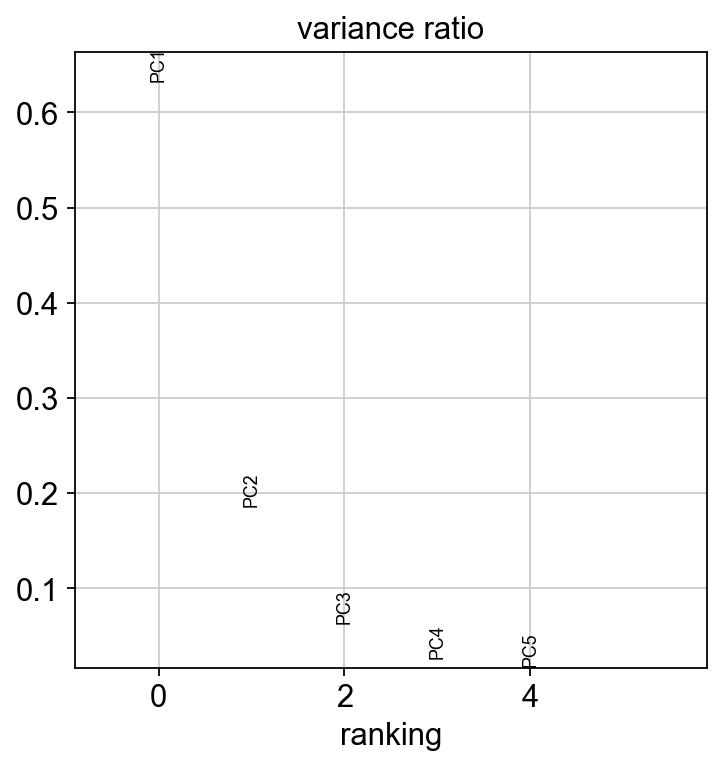

In [11]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca_variance_ratio(adata_bulk, n_pcs=5, log=False)

<Axes: title={'center': 'group'}, xlabel='PC1 (63.22999954223633%)', ylabel='PC2 (18.610000610351562%)'>

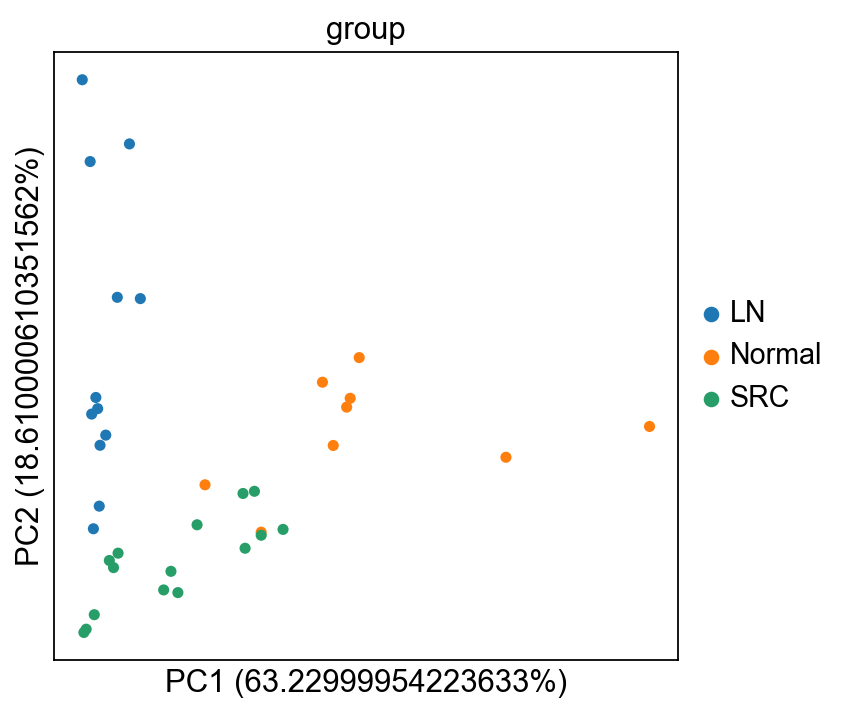

In [12]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca(adata_bulk, 
          color='group',
          size=100,
          annotate_var_explained=True, 
          show=False)

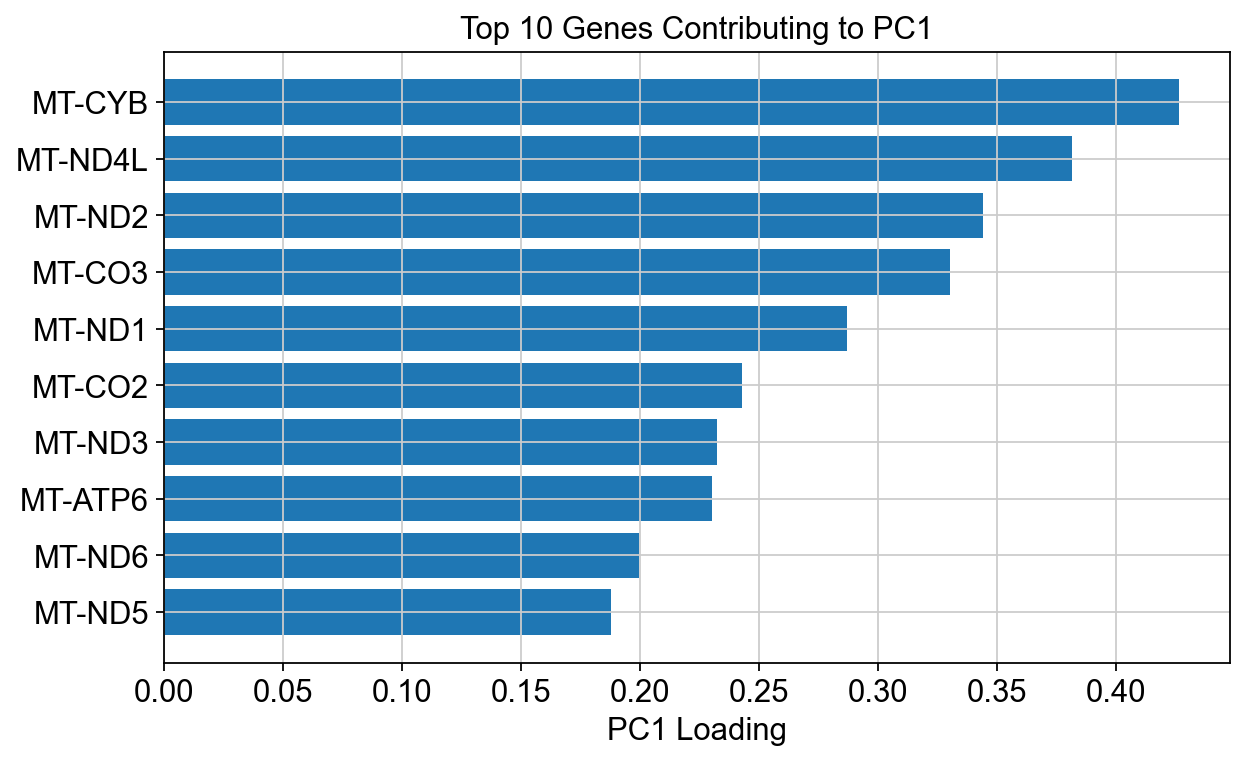

In [13]:
# Get top 10 genes for PC1
pc1 = adata_bulk.varm["PCs"][:, 0]
top_indices = np.argsort(np.abs(pc1))[::-1][:10]
top_genes = adata_bulk.var_names[top_indices]
top_values = pc1[top_indices]

# Plot
plt.figure(figsize=(8, 5))
plt.barh(top_genes[::-1], top_values[::-1])
plt.xlabel("PC1 Loading")
plt.title("Top 10 Genes Contributing to PC1")
plt.tight_layout()
plt.grid(True)
plt.show()

In [14]:
# remove MT- genes from adata
adata_bulk = adata_bulk[:, ~adata_bulk.var_names.str.startswith('MT-')].copy()

In [15]:
adata_bulk.X = adata_bulk.layers['counts'].copy()
sc.pp.normalize_total(adata_bulk, target_sum=1e6)
sc.tl.pca(adata_bulk, n_comps=5)

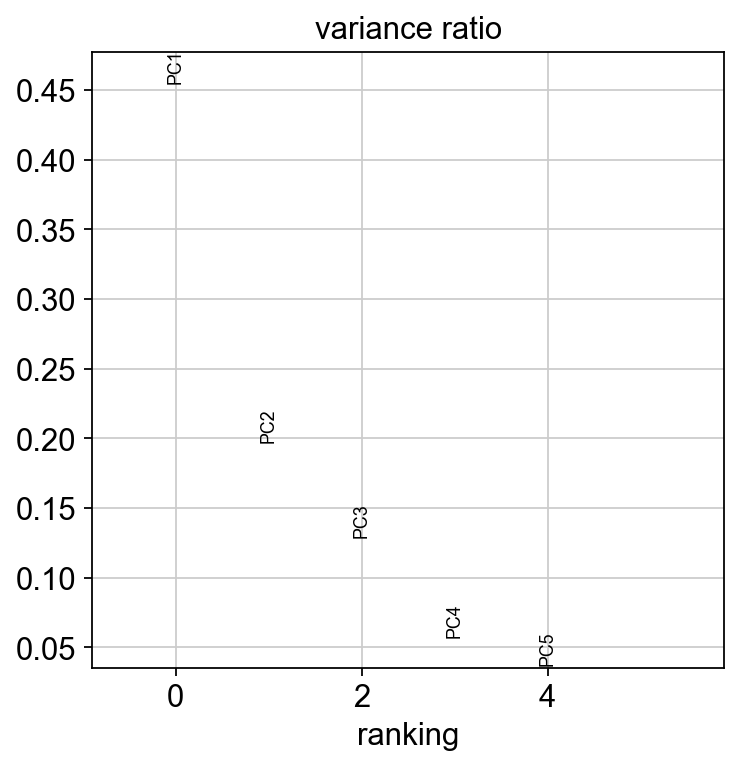

In [16]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca_variance_ratio(adata_bulk, n_pcs=5, log=False)

[<Axes: title={'center': 'group'}, xlabel='PC1 (45.4900016784668%)', ylabel='PC2 (19.760000228881836%)'>,
 <Axes: title={'center': 'annotation_v2'}, xlabel='PC1 (45.4900016784668%)', ylabel='PC2 (19.760000228881836%)'>]

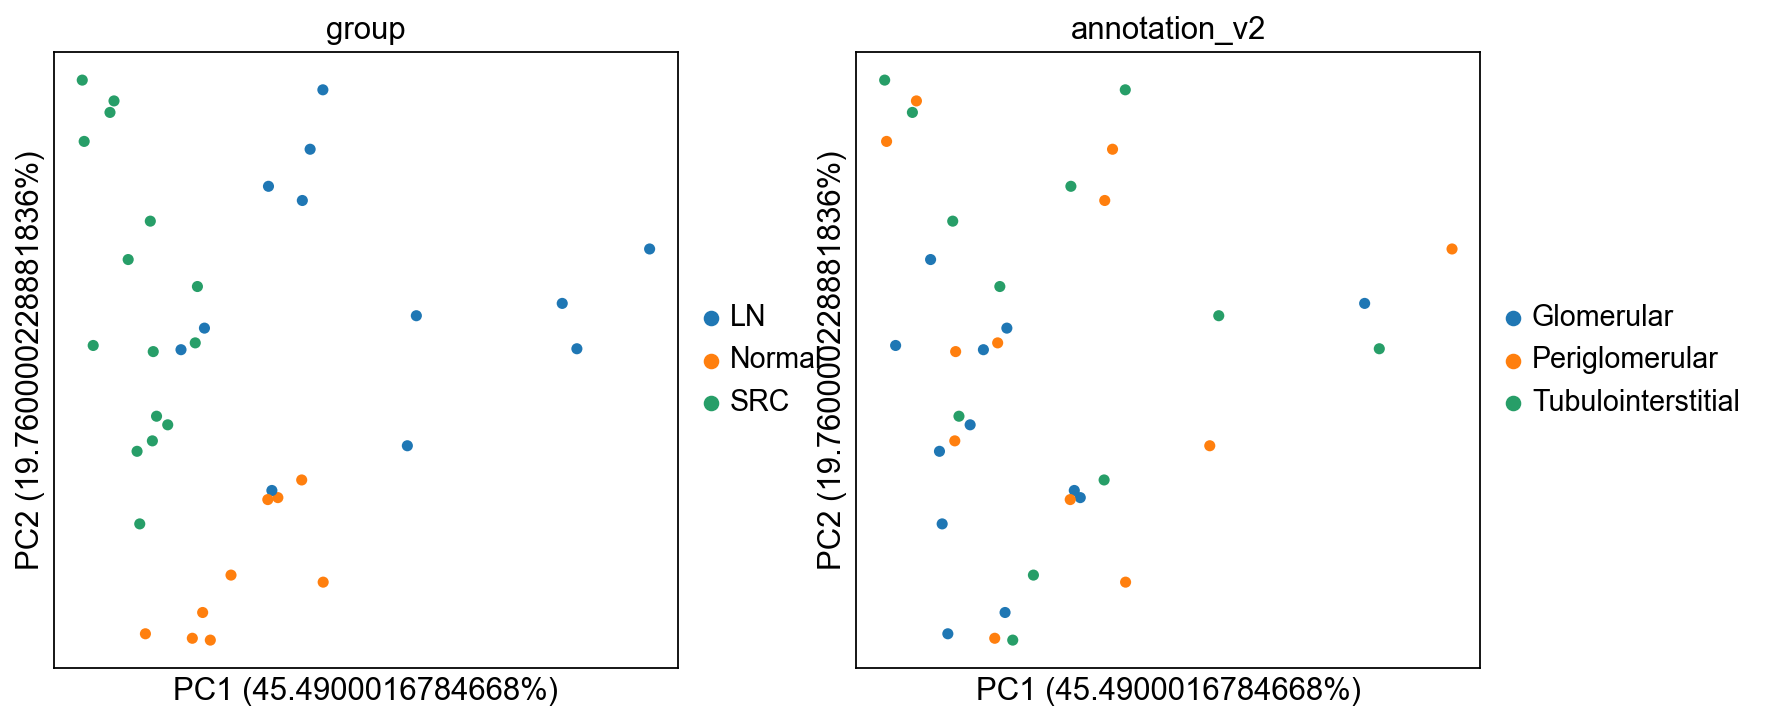

In [17]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca(adata_bulk, 
          color=['group', 'annotation_v2'],
          size=100,
          annotate_var_explained=True, 
          show=False)

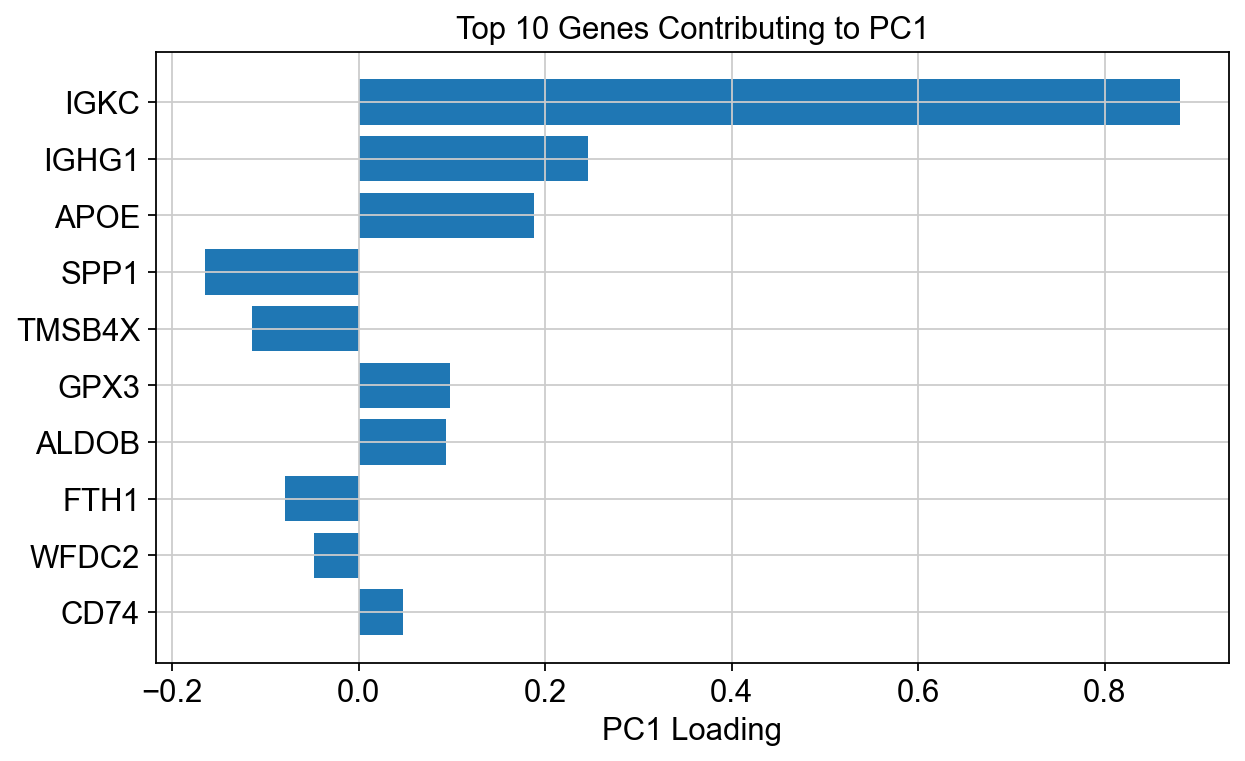

In [18]:
# Get top 10 genes for PC1
pc1 = adata_bulk.varm["PCs"][:, 0]
top_indices = np.argsort(np.abs(pc1))[::-1][:10]
top_genes = adata_bulk.var_names[top_indices]
top_values = pc1[top_indices]

# Plot
plt.figure(figsize=(8, 5))
plt.barh(top_genes[::-1], top_values[::-1])
plt.xlabel("PC1 Loading")
plt.title("Top 10 Genes Contributing to PC1")
plt.tight_layout()
plt.grid(True)
plt.show()

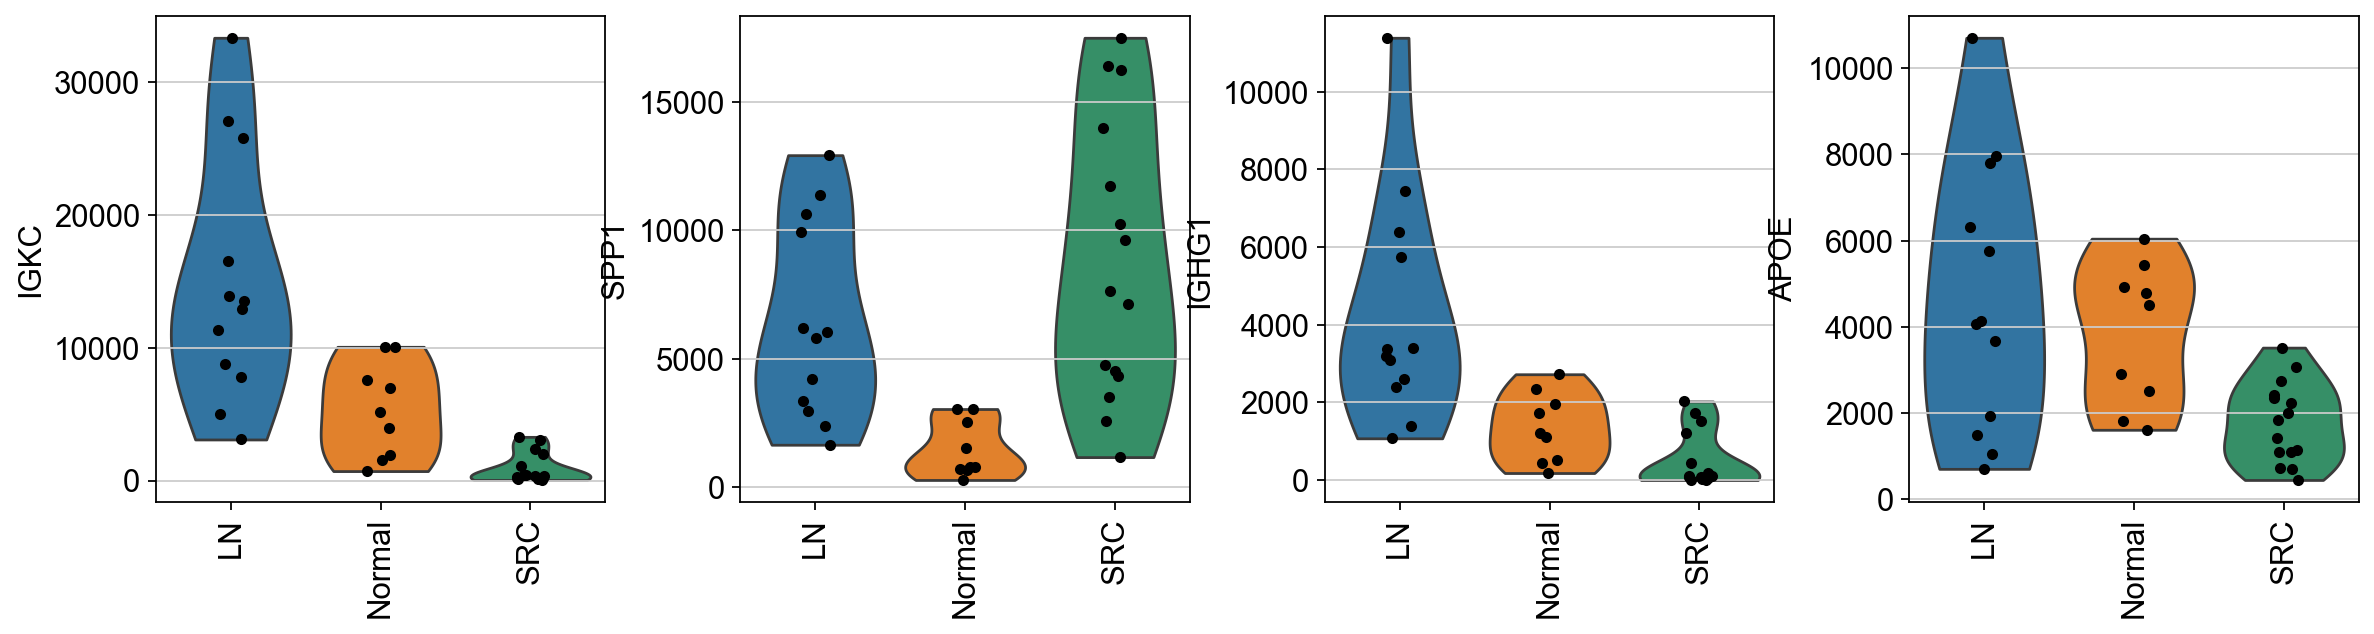

In [19]:
sc.set_figure_params(figsize=(4, 4))

sc.pl.violin(adata_bulk, keys=["IGKC", "SPP1", "IGHG1", "APOE"], 
             use_raw=False, groupby="group", size=5, rotation=90, multi_panel=True)

In [20]:
adata_bulk.obs["annotation_v2"].unique()

['Glomerular', 'Periglomerular', 'Tubulointerstitial']
Categories (3, object): ['Glomerular', 'Periglomerular', 'Tubulointerstitial']

In [21]:
for annotation in adata_bulk.obs["annotation_v2"].unique():
    adata_subset = adata_bulk[adata_bulk.obs["annotation_v2"] == annotation, :].copy()
    
    df_counts = adata_subset.to_df(layer="counts")
    df_meta = adata_subset.obs.copy()
    df_meta = df_meta[["group", "annotation_v2"]]

    df_counts.to_csv(f"{out_dir}/{annotation}_counts_bulk.csv")
    df_meta.to_csv(f"{out_dir}/{annotation}_meta_bulk.csv")

In [22]:
adata_bulk.write_h5ad(f"{out_dir}/adata_bulk.h5ad")